# Used Car Price Prediction

This notebook builds an original regression workflow for the CarDekho vehicle dataset. It covers data quality checks, feature engineering, exploratory analysis, categorical encoding, model comparison, and interpretation.

The target is `selling_price`. The model uses car age, mileage, specifications, seller information, and the extracted manufacturer brand.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

## 2. Load and inspect the data

In [2]:
data_path = Path("cardekho.csv")
if not data_path.exists():
    raise FileNotFoundError(f"Could not find {data_path.resolve()}")

cars = pd.read_csv(data_path)
print(f"Rows: {cars.shape[0]:,} | Columns: {cars.shape[1]}")
display(cars.head())
display(cars.dtypes.to_frame("dtype").T)

Rows: 8,128 | Columns: 12


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
dtype,str,int64,int64,int64,str,str,str,str,float64,float64,str,float64


## 3. Cleaning and feature engineering

Categorical text is normalized with whitespace stripping and title case. Numeric columns are converted with coercion so malformed values become missing and can be imputed later. The reference year is one year after the newest vehicle year in the dataset; this makes `car_age` reproducible without hard-coding today's date.

In [3]:
cars = cars.copy()
missing_before = cars.isna().sum().sort_values(ascending=False)
duplicate_count = cars.duplicated().sum()
print("Missing values before cleaning:")
display(missing_before[missing_before > 0])
print(f"Duplicate rows: {duplicate_count:,}")

# Remove exact duplicate observations.
cars = cars.drop_duplicates().reset_index(drop=True)

categorical_columns = ["fuel", "seller_type", "transmission", "owner"]
for column in categorical_columns:
    cars[column] = cars[column].astype("string").str.strip().str.title()

numeric_columns = [
    "year", "selling_price", "km_driven", "mileage(km/ltr/kg)",
    "engine", "max_power", "seats"
]
for column in numeric_columns:
    cars[column] = pd.to_numeric(cars[column], errors="coerce")

reference_year = int(cars["year"].max()) + 1
cars["car_age"] = (reference_year - cars["year"]).clip(lower=0)
cars["brand"] = cars["name"].astype("string").str.strip().str.split().str[0].str.title()

# Rows without a target cannot be used for supervised learning.
cars = cars.dropna(subset=["selling_price"]).reset_index(drop=True)
print(f"Reference year: {reference_year}")
print(f"Rows after cleaning: {len(cars):,}")
display(cars.isna().sum().sort_values(ascending=False).head(10))

Missing values before cleaning:


seats                 221
mileage(km/ltr/kg)    221
engine                221
max_power             215
dtype: int64

Duplicate rows: 1,202
Reference year: 2021
Rows after cleaning: 6,926


mileage(km/ltr/kg)    208
engine                208
seats                 208
max_power             206
name                    0
year                    0
seller_type             0
fuel                    0
km_driven               0
selling_price           0
dtype: int64

## 4. Exploratory data analysis

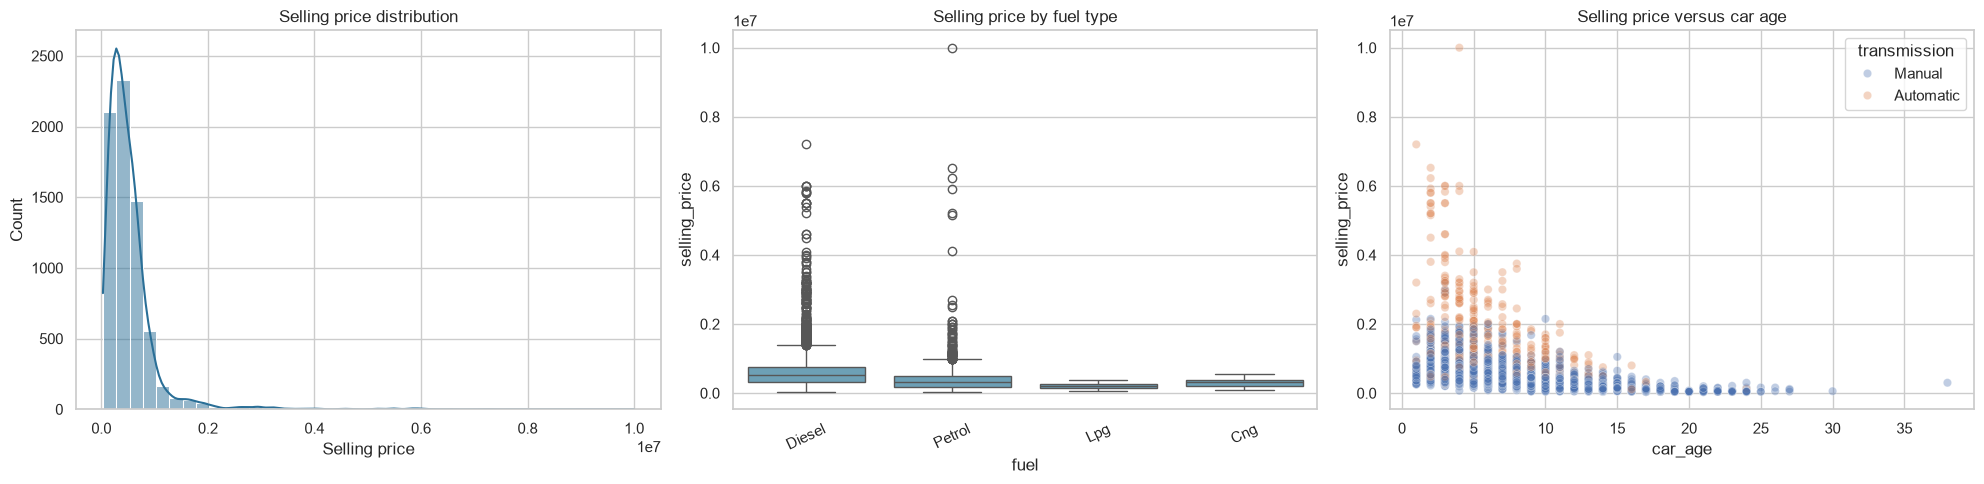

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.histplot(data=cars, x="selling_price", bins=40, kde=True, ax=axes[0], color="#2a6f97")
axes[0].set_title("Selling price distribution")
axes[0].set_xlabel("Selling price")

sns.boxplot(data=cars, x="fuel", y="selling_price", ax=axes[1], color="#61a5c2")
axes[1].set_title("Selling price by fuel type")
axes[1].tick_params(axis="x", rotation=25)

sns.scatterplot(data=cars, x="car_age", y="selling_price", hue="transmission", alpha=0.35, ax=axes[2])
axes[2].set_title("Selling price versus car age")

plt.tight_layout()
plt.show()

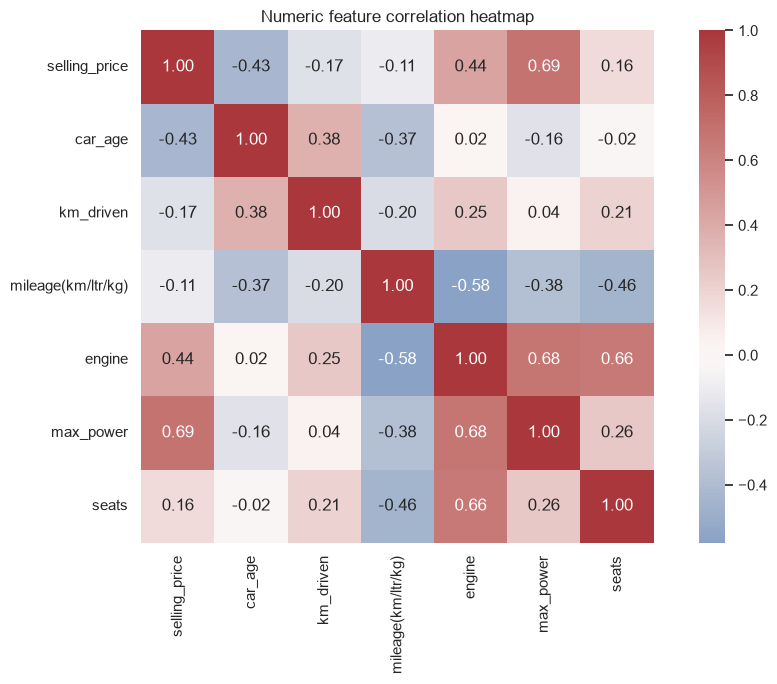

In [5]:
numeric_for_correlation = [
    "selling_price", "car_age", "km_driven", "mileage(km/ltr/kg)",
    "engine", "max_power", "seats"
]
correlation = cars[numeric_for_correlation].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Numeric feature correlation heatmap")
plt.tight_layout()
plt.show()

## 5. Prepare features and preprocessing

The original name and year columns are excluded because brand and age carry the intended information in a more useful form. One-hot encoding is fitted only on the training data through the pipeline.

In [6]:
feature_columns = [
    "car_age", "km_driven", "mileage(km/ltr/kg)", "engine",
    "max_power", "seats", "brand", "fuel", "seller_type",
    "transmission", "owner"
]
X = cars[feature_columns]
y = cars["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = [
    "car_age", "km_driven", "mileage(km/ltr/kg)", "engine",
    "max_power", "seats"
]
categorical_features = [
    "brand", "fuel", "seller_type", "transmission", "owner"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
try:
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
except TypeError:
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse=False))
    ])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

## 6. Train and evaluate regression models

MAE is in the same currency units as the target, RMSE penalizes larger mistakes more strongly, and R-squared reports the proportion of target variance explained.

In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
    )
}

results = []
fitted_pipelines = {}
for model_name, model in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })
    fitted_pipelines[model_name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.3f}"}))
best_model_name = results_df.loc[0, "Model"]
best_pipeline = fitted_pipelines[best_model_name]
print(f"Best model by RMSE: {best_model_name}")

,Model,MAE,RMSE,R2
0,Random Forest,"71,793","121,967",0.932
1,Gradient Boosting,"81,596","127,250",0.926
2,Linear Regression,"139,648","274,727",0.656


Best model by RMSE: Random Forest


## 7. Feature importance for the best tree model

Feature importance is available for tree-based models. If model selection chooses Linear Regression, the chart falls back to the Random Forest model so the requested importance analysis remains interpretable.

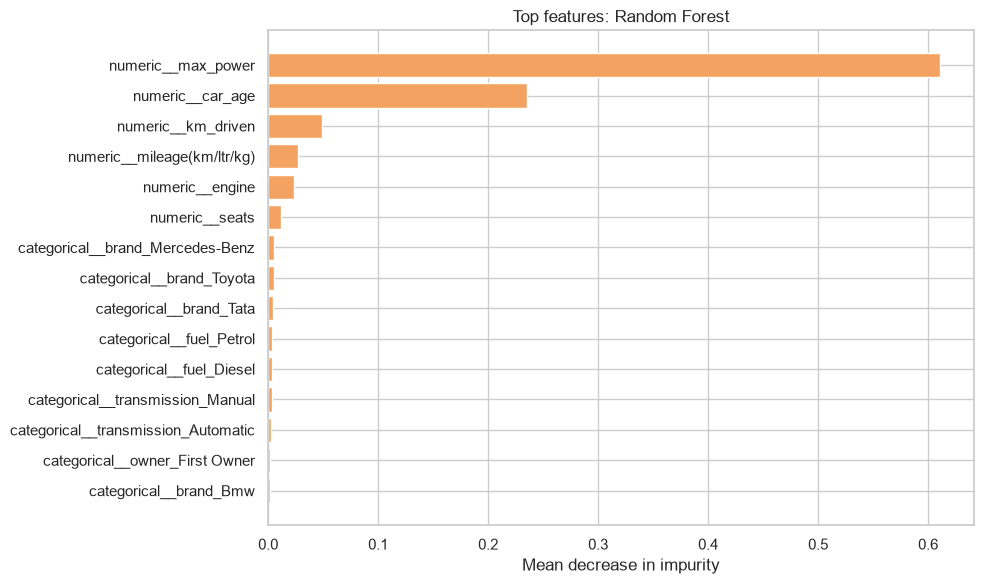

Importance chart uses: Random Forest


In [8]:
importance_model_name = best_model_name
if not hasattr(best_pipeline.named_steps["model"], "feature_importances_"):
    importance_model_name = "Random Forest"
importance_pipeline = fitted_pipelines[importance_model_name]

encoded_names = importance_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = importance_pipeline.named_steps["model"].feature_importances_
importance_df = (
    pd.DataFrame({"feature": encoded_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(15)
    .sort_values("importance")
)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["feature"], importance_df["importance"], color="#f4a261")
plt.xlabel("Mean decrease in impurity")
plt.title(f"Top features: {importance_model_name}")
plt.tight_layout()
plt.show()
print(f"Importance chart uses: {importance_model_name}")

## 8. Conclusion

The table above is the final model comparison. The best model is selected by the lowest RMSE, while MAE and R-squared provide complementary views of its performance. In a production setting, the next steps would be cross-validation, hyperparameter tuning, monitoring for changing market prices, and checking whether rare brands or fuel categories need dedicated handling.